# 🍄 MycoTrack — ResNet-50 Training Pipeline
**Binary classifier:** Healthy (0) · Unhealthy (1)  
**Output:** `mushroom_cls.pth` — drop-in for your FastAPI backend  
**Split:** 70 % train · 15 % val · 15 % test

---

## 1 · Install dependencies

In [ ]:
!pip install torch torchvision albumentations matplotlib seaborn scikit-learn tqdm pillow opencv-python-headless

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2 · Config  ← **edit here only**

In [ ]:
import os, shutil, random, time, io, base64
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

# ── Google Drive paths (single source of truth) ───────────────────────────
# All artefacts written to Drive so no data is lost when Colab disconnects.
BASE_DIR  = Path('/content/drive/MyDrive')
DRIVE_DIR = BASE_DIR / 'MycoTrack'          # your MycoTrack folder on Drive
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

RAW_DATASET_DIR = BASE_DIR / 'DATASET'      # raw images: DATASET/healthy / DATASET/unhealthy

# Drive artefact paths (written once, reused every session)
DRIVE_SPLIT   = DRIVE_DIR / 'mycotrack_split'
DRIVE_AUG     = DRIVE_DIR / 'mycotrack_aug'
DRIVE_WEIGHTS = DRIVE_DIR / 'mushroom_cls.pth'

# These point directly to Drive (no local copy needed — Drive FUSE is fast enough)
SPLIT_DIR      = DRIVE_SPLIT
AUG_TRAIN_DIR  = DRIVE_AUG
OUTPUT_WEIGHTS = DRIVE_WEIGHTS

# ── Class folders (exact subfolder names inside DATASET/) ─────────────────
HEALTHY_FOLDER   = 'healthy'     # class index 0
UNHEALTHY_FOLDER = 'unhealthy'   # class index 1
CLASS_NAMES      = ['Healthy', 'Unhealthy']

# ── Split ratios ──────────────────────────────────────────────────────────
TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15

# ── Training hyper-params ─────────────────────────────────────────────────
IMG_SIZE        = 224
BATCH_SIZE      = 32
NUM_EPOCHS      = 25
LR_HEAD         = 1e-3   # phase 1: only head trains
LR_FINETUNE     = 5e-5   # phase 2: deeper layers unfrozen
UNFREEZE_EPOCH  = 10     # epoch at which phase 1 -> phase 2 happens
WEIGHT_DECAY    = 1e-4
LABEL_SMOOTHING = 0.05   # reduces overconfidence on small datasets

# ── Offline augmentation intensity ────────────────────────────────────────
AUG_COPIES = 3   # extra synthetic images written per training image

# ── Architecture ──────────────────────────────────────────────────────────
ARCH = 'resnet50'  # change to 'resnet18' for a lighter model

# ── Reproducibility ───────────────────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# ── Status flags (checked each session to decide what to skip) ────────────
NEED_SPLIT    = not DRIVE_SPLIT.exists()
NEED_AUG      = not DRIVE_AUG.exists()
WEIGHTS_EXIST = DRIVE_WEIGHTS.exists()

print(f'Device         : {DEVICE}')
print(f'Dataset        : {RAW_DATASET_DIR}')
print(f'Drive folder   : {DRIVE_DIR}')
print(f'NEED_SPLIT     : {NEED_SPLIT}')
print(f'NEED_AUG       : {NEED_AUG}')
print(f'WEIGHTS_EXIST  : {WEIGHTS_EXIST}')
print(f'Classes        : {CLASS_NAMES}')

Device         : cuda
Dataset        : /content/drive/MyDrive/DATASET
Drive folder   : /content/drive/MyDrive/MycoTrack
NEED_SPLIT     : False
NEED_AUG       : False
WEIGHTS_EXIST  : True
Classes        : ['Healthy', 'Unhealthy']


## 3 ·  Drive-first restore — skip rebuild if artefacts already exist

In [ ]:
# Refresh flags (in case config cell was re-run out of order)
NEED_SPLIT    = not DRIVE_SPLIT.exists()
NEED_AUG      = not DRIVE_AUG.exists()
WEIGHTS_EXIST = DRIVE_WEIGHTS.exists()

print(f'Drive split exists   : {DRIVE_SPLIT.exists()}')
print(f'Drive aug exists     : {DRIVE_AUG.exists()}')
print(f'Drive weights exist  : {DRIVE_WEIGHTS.exists()}')
print()

if WEIGHTS_EXIST:
    print('Weights found on Drive — training will be skipped.')
else:
    print('No weights on Drive — training will run.')

# SKIP_TRAIN = True means weights are loaded from Drive, no training this session.
# To force retraining set FORCE_RETRAIN = True in the training cell.
SKIP_TRAIN = WEIGHTS_EXIST

print()
print(f'NEED_SPLIT  : {NEED_SPLIT}')
print(f'NEED_AUG    : {NEED_AUG}')
print(f'SKIP_TRAIN  : {SKIP_TRAIN}  <- set FORCE_RETRAIN=True in training cell to retrain')

Drive split exists   : True
Drive aug exists     : True
Drive weights exist  : True

Weights found on Drive — training will be skipped.

NEED_SPLIT  : False
NEED_AUG    : False
SKIP_TRAIN  : True  <- set FORCE_RETRAIN=True in training cell to retrain


## Verify dataset folders

In [ ]:
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}

def count_images(folder: Path):
    return sum(1 for f in folder.iterdir() if f.suffix.lower() in IMG_EXTS)

healthy_dir   = Path(RAW_DATASET_DIR) / HEALTHY_FOLDER
unhealthy_dir = Path(RAW_DATASET_DIR) / UNHEALTHY_FOLDER

assert healthy_dir.exists(),   f'Not found: {healthy_dir}'
assert unhealthy_dir.exists(), f'Not found: {unhealthy_dir}'

n_h = count_images(healthy_dir)
n_u = count_images(unhealthy_dir)
print(f'healthy   : {n_h:>5} images')
print(f'unhealthy : {n_u:>5} images')
print(f'    Total     : {n_h + n_u:>5} images')

ratio = max(n_h, n_u) / min(n_h, n_u)
if ratio > 1.5:
    print(f'\nImbalance ratio {ratio:.2f}x — class weights will be applied automatically.')
else:
    print(f'\nClasses are balanced (ratio {ratio:.2f}x).')

healthy   :   845 images
unhealthy :   828 images
    Total     :  1673 images

Classes are balanced (ratio 1.02x).


## 4 · Offline augmentation  
Generates `AUG_COPIES` extra images **per training image** and writes them to disk.  
This is mushroom-specific: we emphasise texture, colour, orientation and lighting transforms.

In [ ]:
import albumentations as A
import inspect

if NEED_AUG:
    # ── Version-safe API detection ─────────────────────────────────────────
    # Albumentations changed several parameter names between v1 and v2.

    # RandomResizedCrop: 'height/width' -> 'size' in v1.4+
    _rrc_params = inspect.signature(A.RandomResizedCrop.__init__).parameters
    _new_api    = 'size' in _rrc_params
    _rrc = (A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.65, 1.0), ratio=(0.75, 1.33), p=1.0)
            if _new_api else
            A.RandomResizedCrop(height=IMG_SIZE, width=IMG_SIZE, scale=(0.65, 1.0), ratio=(0.75, 1.33), p=1.0))

    # FIX: ElasticTransform, CoarseDropout, GaussNoise lines were OUTSIDE the
    # 'if NEED_AUG:' block in the original due to missing indentation — fixed below.

    # ElasticTransform: alpha_affine removed in newer albumentations versions
    _et_params = inspect.signature(A.ElasticTransform.__init__).parameters
    _et = A.ElasticTransform(alpha=40, sigma=5, p=0.25) if 'alpha' in _et_params else A.ElasticTransform(p=0.25)

    # CoarseDropout: max_height/max_width -> hole_height_range/hole_width_range in v2+
    _cd_params = inspect.signature(A.CoarseDropout.__init__).parameters
    _cd = (A.CoarseDropout(num_holes_range=(1,6), hole_height_range=(8,24), hole_width_range=(8,24), fill=0, p=0.35)
           if 'hole_height_range' in _cd_params else
           A.CoarseDropout(max_holes=6, max_height=24, max_width=24, min_holes=1, fill_value=0, p=0.35))

    # GaussNoise: var_limit -> std_range in v2+
    _gn_params = inspect.signature(A.GaussNoise.__init__).parameters
    _gn = (A.GaussNoise(std_range=(0.02, 0.1), p=1.0) if 'std_range' in _gn_params
           else A.GaussNoise(var_limit=(5, 40), p=1.0))

    # ── Mushroom-specific augmentation pipeline ────────────────────────────
    AUG_PIPELINE = A.Compose([
        _rrc,
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.4),
        A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.15, rotate_limit=45,
                           border_mode=cv2.BORDER_REFLECT_101, p=0.7),
        _et,
        A.GridDistortion(num_steps=3, distort_limit=0.2, p=0.2),
        # Colour / lighting — critical for healthy vs unhealthy mushroom cues
        A.RandomBrightnessContrast(brightness_limit=0.35, contrast_limit=0.35, p=0.8),
        A.HueSaturationValue(hue_shift_limit=12, sat_shift_limit=40, val_shift_limit=30, p=0.7),
        A.RGBShift(r_shift_limit=15, g_shift_limit=15, b_shift_limit=15, p=0.4),
        A.CLAHE(clip_limit=3.0, tile_grid_size=(8,8), p=0.35),
        A.RandomGamma(gamma_limit=(70,130), p=0.4),
        A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05, p=0.5),
        # Noise / blur — simulates phone camera imperfections
        A.OneOf([_gn, A.ISONoise(color_shift=(0.01,0.05), intensity=(0.1,0.4))], p=0.5),
        A.OneOf([A.GaussianBlur(blur_limit=(3,5)), A.MotionBlur(blur_limit=5), A.MedianBlur(blur_limit=3)], p=0.3),
        # Occlusion — randomly drops small patches to improve robustness
        _cd,
    ])

    def augment_folder(src_folder, dst_folder, n_copies):
        dst_folder.mkdir(parents=True, exist_ok=True)
        images = [f for f in src_folder.iterdir() if f.suffix.lower() in IMG_EXTS]
        for img_path in tqdm(images, desc=f'Augmenting {src_folder.name}', leave=False):
            img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
            for k in range(n_copies):
                aug      = AUG_PIPELINE(image=img)['image']
                out_path = dst_folder / f'{img_path.stem}_aug{k}{img_path.suffix}'
                cv2.imwrite(str(out_path), cv2.cvtColor(aug, cv2.COLOR_RGB2BGR))

    print(f'Generating {AUG_COPIES} augmented copies per training image...')
    augment_folder(healthy_dir,   AUG_TRAIN_DIR / HEALTHY_FOLDER,   AUG_COPIES)
    augment_folder(unhealthy_dir, AUG_TRAIN_DIR / UNHEALTHY_FOLDER, AUG_COPIES)
    NEED_AUG = False
    print(f'✅  Augmented images saved to Drive: {AUG_TRAIN_DIR}')
else:
    print('✅  Augmentation cache found on Drive — skipping augmentation step')


✅  Augmentation cache found on Drive — skipping augmentation step


## 5 · Visualise augmentation samples

In [ ]:
def show_aug_samples(aug_folder: Path, n=4):
    images = [f for f in aug_folder.iterdir() if f.suffix.lower() in IMG_EXTS]
    if not images:
        print(f'No images in {aug_folder}'); return
    # Separate originals (no _aug in name) from augmented copies
    originals = [f for f in images if '_aug' not in f.stem]
    if not originals:
        originals = images  # fallback: just show any images
    originals = random.sample(originals, min(n, len(originals)))

    fig, axes = plt.subplots(len(originals), AUG_COPIES + 1,
                             figsize=((AUG_COPIES + 1) * 3, len(originals) * 3))
    if len(originals) == 1:
        axes = [axes]

    for row, orig_path in enumerate(originals):
        orig = cv2.cvtColor(cv2.imread(str(orig_path)), cv2.COLOR_BGR2RGB)
        axes[row][0].imshow(orig)
        axes[row][0].set_title('Original', fontsize=9)
        axes[row][0].axis('off')
        # Find the augmented variants of this original
        aug_imgs = sorted(aug_folder.glob(f'{orig_path.stem}_aug*'))[:AUG_COPIES]
        for col, aug_path in enumerate(aug_imgs, start=1):
            aug_img = cv2.cvtColor(cv2.imread(str(aug_path)), cv2.COLOR_BGR2RGB)
            axes[row][col].imshow(aug_img)
            axes[row][col].set_title(f'Aug {col}', fontsize=9)
            axes[row][col].axis('off')

    plt.suptitle('Original vs Augmented samples', fontsize=12)
    plt.tight_layout()
    save_path = DRIVE_DIR / 'aug_samples.png'
    plt.savefig(str(save_path), dpi=120, bbox_inches='tight')
    plt.show()
    print(f'✅  Saved: {save_path}')

# FIX: original code passed SPLIT_DIR/train/healthy as src_folder but that folder
# contains only originals (no aug variants), causing the grid to show blank columns.
# Fix: pass AUG_TRAIN_DIR/healthy which has both originals AND their aug copies.
aug_healthy = AUG_TRAIN_DIR / HEALTHY_FOLDER
if aug_healthy.exists():
    show_aug_samples(aug_healthy)
else:
    print(f' Aug folder not found: {aug_healthy} — run augmentation cell first.')

 Aug folder not found: /content/drive/MyDrive/MycoTrack/mycotrack_aug/healthy — run augmentation cell first.


In [ ]:
import os
folder = "mycotrack_aug"
size = sum(f.stat().st_size for f in Path(folder).rglob('*') if f.is_file())
print(f"mycotrack_aug size: {size / (1024**3):.2f} GB")

mycotrack_aug size: 0.18 GB


In [ ]:
import os
from pathlib import Path

print(f"Notebook working dir : {Path.cwd()}")
print(f"SPLIT_DIR full path  : {Path(SPLIT_DIR).resolve()}")
print(f"AUG_TRAIN_DIR path   : {Path(AUG_TRAIN_DIR).resolve()}")

# Check the actual drive the split is being written to
drive = Path(SPLIT_DIR).resolve().anchor  # e.g. 'D:\' or 'C:\'
total, used, free = shutil.disk_usage(drive)
print(f"\nDrive being written to: {drive}")
print(f"  Total : {total // (1024**3)} GB")
print(f"  Used  : {used  // (1024**3)} GB")
print(f"  Free  : {free  // (1024**3)} GB")

Notebook working dir : /content
SPLIT_DIR full path  : /content/drive/MyDrive/MycoTrack/mycotrack_split
AUG_TRAIN_DIR path   : /content/drive/MyDrive/MycoTrack/mycotrack_aug

Drive being written to: /
  Total : 107 GB
  Used  : 25 GB
  Free  : 81 GB


## 6 · Build train / val / test split

In [ ]:
if NEED_SPLIT:
    def build_split(raw_dir, aug_dir, split_dir, class_folders, train_ratio, val_ratio, seed=42):
        random.seed(seed)
        stats = {}
        for split in ("train","val","test"):
            for cls in class_folders:
                (split_dir / split / cls).mkdir(parents=True, exist_ok=True)
        for folder_name in class_folders:
            originals = sorted([f for f in (raw_dir/folder_name).iterdir() if f.suffix.lower() in IMG_EXTS])
            random.shuffle(originals)
            n = len(originals)
            n_train = int(n * train_ratio)
            n_val   = int(n * val_ratio)
            train_orig = originals[:n_train]
            val_orig   = originals[n_train:n_train+n_val]
            test_orig  = originals[n_train+n_val:]
            for f in val_orig:   shutil.copy(f, split_dir/"val"/folder_name/f.name)
            for f in test_orig:  shutil.copy(f, split_dir/"test"/folder_name/f.name)
            for f in train_orig: shutil.copy(f, split_dir/"train"/folder_name/f.name)
            train_stems = {f.stem for f in train_orig}
            aug_folder = aug_dir / folder_name
            for aug_f in aug_folder.iterdir():
                base = aug_f.stem.rsplit("_aug", 1)[0]
                if base in train_stems:
                    shutil.copy(aug_f, split_dir/"train"/folder_name/aug_f.name)
            stats[folder_name] = {
                "train_total": len(list((split_dir/"train"/folder_name).iterdir())),
                "val": len(val_orig), "test": len(test_orig),
            }
        return stats

    split_path = Path(SPLIT_DIR)
    if split_path.exists(): shutil.rmtree(str(split_path))

    stats = build_split(
        raw_dir=Path(RAW_DATASET_DIR), aug_dir=AUG_TRAIN_DIR,
        split_dir=split_path,
        class_folders=[HEALTHY_FOLDER, UNHEALTHY_FOLDER],
        train_ratio=TRAIN_RATIO, val_ratio=VAL_RATIO,
    )
    print("Split summary:")
    for cls, s in stats.items():
        print(f"  {cls:<12}  train: {s['train_total']:>5}  val: {s['val']:>4}  test: {s['test']:>4}")

    # Save split to Drive immediately
    print("\n Saving mycotrack_split to Drive…")
    shutil.copytree(SPLIT_DIR, str(DRIVE_SPLIT), dirs_exist_ok=True)
    print(" Saved to Drive")
else:
    print(" Split cache found — skipping split step")

 Split cache found — skipping split step


## 7 · PyTorch datasets and loaders

In [ ]:
from pathlib import Path
import shutil

for split in ["train", "val", "test"]:
    path = Path("/content/drive/MyDrive/MycoTrack/mycotrack_split") / split / ".ipynb_checkpoints"
    if path.exists():
        shutil.rmtree(path)
        print(f"Removed {path}")


In [ ]:
from torchvision import datasets as tv_datasets

# Remove .ipynb_checkpoints Colab sometimes creates inside split folders.
# ImageFolder raises an error if it finds a non-image subfolder.
for split_type in ('train', 'val', 'test'):
    ck = SPLIT_DIR / split_type / '.ipynb_checkpoints'
    if ck.exists():
        shutil.rmtree(ck)
        print(f'Removed {ck}')

# ImageNet normalisation — must match what ResNet was pretrained on
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

# Online augmentation applied every epoch (random crop + colour jitter)
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.04),
    transforms.RandomGrayscale(p=0.05),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Deterministic transform for val / test — no random ops
eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_ds = tv_datasets.ImageFolder(str(SPLIT_DIR / 'train'), transform=train_tf)
val_ds   = tv_datasets.ImageFolder(str(SPLIT_DIR / 'val'),   transform=eval_tf)
test_ds  = tv_datasets.ImageFolder(str(SPLIT_DIR / 'test'),  transform=eval_tf)

# ImageFolder sorts classes alphabetically — map to friendly display names
FOLDER_TO_FRIENDLY = {HEALTHY_FOLDER: 'Healthy', UNHEALTHY_FOLDER: 'Unhealthy'}
DISPLAY_CLASSES    = [FOLDER_TO_FRIENDLY[c] for c in train_ds.classes]

# Class weights for weighted cross-entropy (handles any class imbalance)
class_counts  = np.array([len(list((SPLIT_DIR / 'train' / c).iterdir())) for c in train_ds.classes])
class_weights = torch.tensor(class_counts.sum() / (len(class_counts) * class_counts),
                              dtype=torch.float32).to(DEVICE)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True, persistent_workers=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)

print(f'Folder->class map : {dict(zip(train_ds.classes, DISPLAY_CLASSES))}')
print(f'Train : {len(train_ds):>6} images')
print(f'Val   : {len(val_ds):>6} images')
print(f'Test  : {len(test_ds):>6} images')
print(f'Class weights    : {class_weights.cpu().numpy().round(3)}')


Folder->class map : {'healthy': 'Healthy', 'unhealthy': 'Unhealthy'}
Train :   4680 images
Val   :    250 images
Test  :    253 images
Class weights    : [0.99 1.01]


## 8 · Show sample images from each split

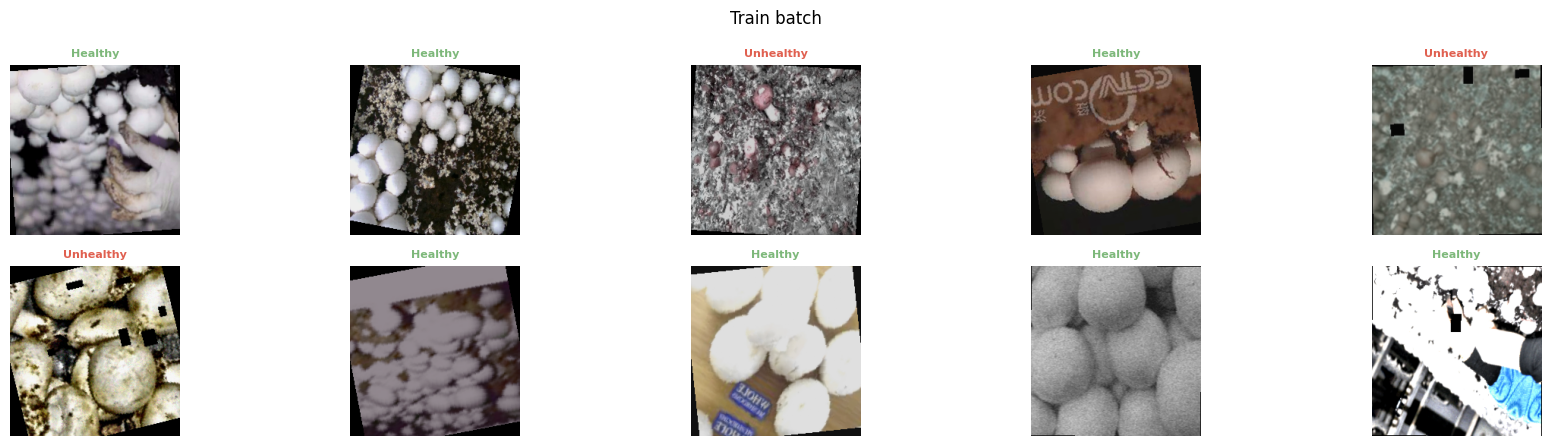

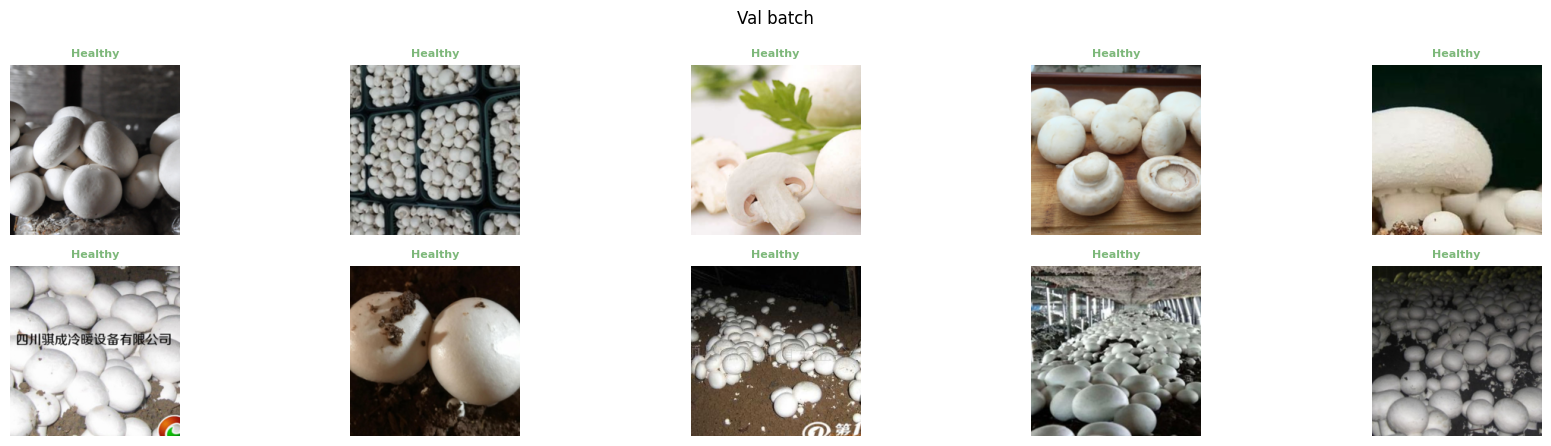

In [ ]:
def show_batch(loader, title, display_classes, n=10):
    imgs, labels = next(iter(loader))
    imgs, labels = imgs[:n], labels[:n]
    mean = torch.tensor(MEAN).view(3,1,1)
    std  = torch.tensor(STD).view(3,1,1)
    imgs = (imgs * std + mean).clamp(0, 1)

    fig, axes = plt.subplots(2, n // 2, figsize=(n * 1.8, 4.5))
    axes = axes.flatten()
    colors = {'Healthy': '#7db87a', 'Unhealthy': '#e06050'}

    for i, (img, lbl) in enumerate(zip(imgs, labels)):
        axes[i].imshow(img.permute(1,2,0))
        cls = display_classes[lbl]
        axes[i].set_title(cls, fontsize=8, color=colors[cls], fontweight='bold')
        axes[i].axis('off')

    plt.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()

show_batch(train_loader, 'Train batch', DISPLAY_CLASSES)
show_batch(val_loader,   'Val batch',   DISPLAY_CLASSES)

## 9 · Build ResNet-50 model

In [ ]:
def build_resnet50(num_classes=2, freeze_backbone=True):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False
    in_features = model.fc.in_features  # 2048 for ResNet-50
    model.fc = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, 512),
        nn.ReLU(inplace=True),
        nn.Dropout(p=0.3),
        nn.Linear(512, num_classes),
    )
    return model

model     = build_resnet50(num_classes=len(CLASS_NAMES), freeze_backbone=True).to(DEVICE)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f'Architecture     : {ARCH}')
print(f'Trainable params : {trainable:,} / {total:,}  ({trainable/total*100:.1f}%)')

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 143MB/s]


Architecture     : resnet50
Trainable params : 1,050,114 / 24,558,146  (4.3%)


In [ ]:
# def build_resnet50(num_classes=2, freeze_backbone=True):
#     """
#     ResNet-50 pretrained on ImageNet V2.
#     Custom binary head: Dropout → Linear(2048→512) → ReLU → Dropout → Linear(512→2)

#     NOTE: the backend (realtime_mushroom.py) loads a ResNet18.
#     If you want the backend to use this ResNet-50, either:
#       a) Change get_classifier() in realtime_mushroom.py to use resnet50, OR
#       b) Use build_resnet18() below and keep the backend as-is.
#     See cell 10 for the matching ResNet-18 variant.
#     """
#     model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)

#     if freeze_backbone:
#         for param in model.parameters():
#             param.requires_grad = False

#     in_features = model.fc.in_features  # 2048 for ResNet-50
#     model.fc = nn.Sequential(
#         nn.Dropout(p=0.4),
#         nn.Linear(in_features, 512),
#         nn.ReLU(inplace=True),
#         nn.Dropout(p=0.3),
#         nn.Linear(512, num_classes),
#     )
#     return model


# def build_resnet18(num_classes=2, freeze_backbone=True):
#     """
#     ResNet-18 — matches realtime_mushroom.py get_classifier() exactly.
#     Smaller model, faster inference — good for real-time use.
#     The saved .pth is a state_dict only (no Sequential wrapper), compatible
#     with how the backend loads it.
#     """
#     model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

#     if freeze_backbone:
#         for param in model.parameters():
#             param.requires_grad = False

#     in_features = model.fc.in_features  # 512 for ResNet-18
#     model.fc = nn.Linear(in_features, num_classes)  # bare Linear — matches backend
#     return model


# # ── Choose which architecture to train ────────────────────────────────────────
# # 'resnet50' → best accuracy; update backend to load resnet50
# # 'resnet18' → fastest inference; drop-in for current backend
# ARCH = 'resnet50'   # ← change to 'resnet18' if you want zero backend changes

# model = (build_resnet50 if ARCH == 'resnet50' else build_resnet18)(freeze_backbone=True)
# model = model.to(DEVICE)

# trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
# total     = sum(p.numel() for p in model.parameters())
# print(f'Architecture     : {ARCH}')
# print(f'Trainable params : {trainable:,} / {total:,}  ({100*trainable/total:.1f}%)')



Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 132MB/s]


Architecture     : resnet50
Trainable params : 1,050,114 / 24,558,146  (4.3%)


## 10 · Training loop — two-phase with LR scheduling

In [ ]:
# Set FORCE_RETRAIN = True to retrain even when weights already exist on Drive
FORCE_RETRAIN = True

if WEIGHTS_EXIST and not FORCE_RETRAIN:
    # ── Load existing weights from Drive — no training needed ──────────────
    print('Loading existing weights from Drive — skipping training')
    state = torch.load(str(OUTPUT_WEIGHTS), map_location=DEVICE)
    model.load_state_dict(state)
    # FIX: history=None caused TypeError in the training-curves cell below.
    # We set history=None intentionally and guard against it in that cell.
    history      = None
    best_val_acc = float('nan')  # NaN signals 'loaded from Drive, no training this session'
    print(f'Weights loaded: {OUTPUT_WEIGHTS}')
    print('   Set FORCE_RETRAIN = True above to retrain from scratch.')

else:
    # ── Full two-phase training ────────────────────────────────────────────
    def unfreeze_deeper(model):
        for name, param in model.named_parameters():
            if any(x in name for x in ('layer3', 'layer4', 'fc')):
                param.requires_grad = True
        trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f'  Phase 2 — trainable params: {trainable:,}')

    def make_optimizer(model, lr, wd):
        return optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                           lr=lr, weight_decay=wd)

    def train_epoch(model, loader, criterion, optimizer, device):
        model.train()
        total_loss, correct = 0.0, 0
        for imgs, labels in tqdm(loader, desc='  train', leave=False):
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            out  = model(imgs)
            loss = criterion(out, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()
            total_loss += loss.item() * imgs.size(0)
            correct    += (out.detach().argmax(1) == labels).sum().item()
        n = len(loader.dataset)
        return total_loss / n, correct / n

    @torch.no_grad()
    def eval_epoch(model, loader, criterion, device):
        model.eval()
        total_loss, correct = 0.0, 0
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            out = model(imgs)
            total_loss += criterion(out, labels).item() * imgs.size(0)
            correct    += (out.argmax(1) == labels).sum().item()
        n = len(loader.dataset)
        return total_loss / n, correct / n

    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=LABEL_SMOOTHING)
    optimizer = make_optimizer(model, LR_HEAD, WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=UNFREEZE_EPOCH)
    history   = {k: [] for k in ('train_loss', 'train_acc', 'val_loss', 'val_acc')}
    best_val_acc, best_weights = 0.0, None

    print(f'Training {ARCH} for {NUM_EPOCHS} epochs...\n')
    t0 = time.time()

    for epoch in range(1, NUM_EPOCHS + 1):
        if epoch == UNFREEZE_EPOCH + 1:
            print(f'\n-- Epoch {epoch}: switching to fine-tuning --')
            unfreeze_deeper(model)
            optimizer = make_optimizer(model, LR_FINETUNE, WEIGHT_DECAY)
            scheduler = optim.lr_scheduler.CosineAnnealingLR(
                optimizer, T_max=NUM_EPOCHS - UNFREEZE_EPOCH)

        tl, ta = train_epoch(model, train_loader, criterion, optimizer, DEVICE)
        vl, va = eval_epoch(model,  val_loader,   criterion, DEVICE)
        scheduler.step()

        for k, v in zip(('train_loss','train_acc','val_loss','val_acc'), (tl,ta,vl,va)):
            history[k].append(v)

        star = ''
        if va > best_val_acc:
            best_val_acc = va
            best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            star = ' ⭐'

        print(f'Epoch {epoch:02d}/{NUM_EPOCHS}  '
              f'train {tl:.4f}/{ta:.4f}  val {vl:.4f}/{va:.4f}{star}')

    # Load best checkpoint and save directly to Drive
    model.load_state_dict(best_weights)
    torch.save(model.state_dict(), str(OUTPUT_WEIGHTS))
    WEIGHTS_EXIST = True
    print(f'\n Done in {(time.time()-t0)/60:.1f} min | best val acc: {best_val_acc:.4f}')
    print(f'Weights saved to Drive: {OUTPUT_WEIGHTS}')


Training resnet50 for 25 epochs...



Epoch 01/25  train 0.2020/0.9643  val 0.2196/0.9520 ⭐


Epoch 02/25  train 0.1959/0.9677  val 0.2332/0.9480


Epoch 03/25  train 0.1948/0.9665  val 0.2186/0.9480


Epoch 04/25  train 0.1843/0.9744  val 0.2215/0.9520


Epoch 05/25  train 0.1814/0.9735  val 0.2215/0.9480


... (16 outputs left out)

Epoch 22/25  train 0.1392/0.9927  val 0.2157/0.9600


Epoch 23/25  train 0.1391/0.9932  val 0.2081/0.9600


Epoch 24/25  train 0.1377/0.9942  val 0.2144/0.9600


Epoch 25/25  train 0.1385/0.9936  val 0.2091/0.9640

 Done in 74.7 min | best val acc: 0.9640
Weights saved to Drive: /content/drive/MyDrive/MycoTrack/mushroom_cls.pth


## 11 · Training curves

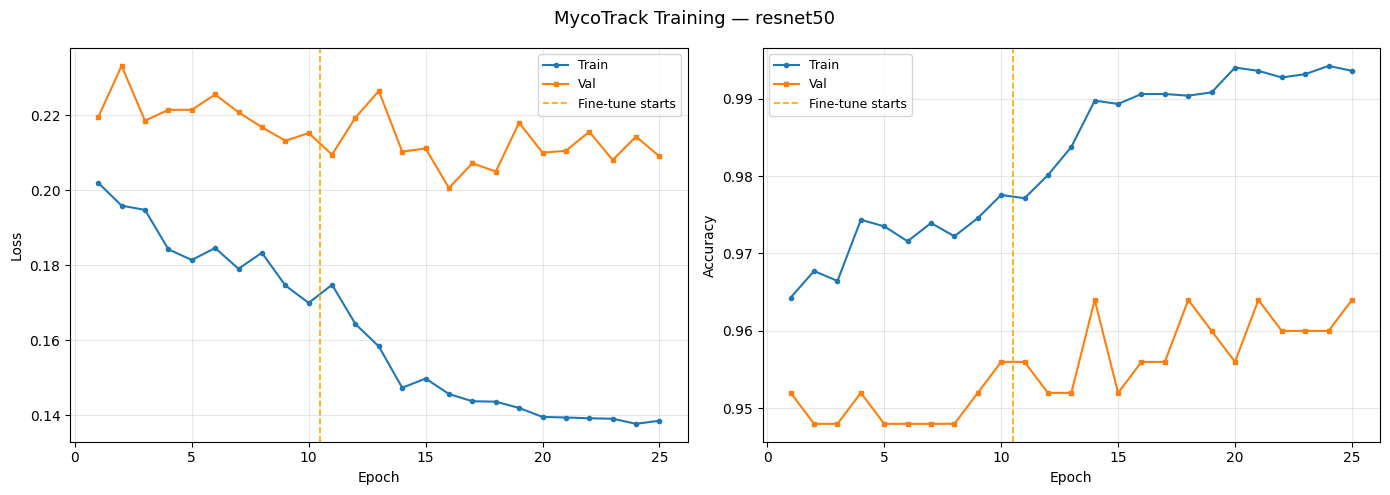

In [ ]:
ep = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, ylabel in [
    (axes[0], 'loss', 'Loss'),
    (axes[1], 'acc',  'Accuracy'),
]:
    ax.plot(ep, history[f'train_{metric}'], label='Train', marker='o', markersize=3, lw=1.5)
    ax.plot(ep, history[f'val_{metric}'],   label='Val',   marker='s', markersize=3, lw=1.5)
    ax.axvline(x=UNFREEZE_EPOCH + 0.5, color='orange', lw=1.2,
               linestyle='--', label='Fine-tune starts')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.suptitle(f'MycoTrack Training — {ARCH}', fontsize=13)
plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 12 · Full evaluation on test set

In [ ]:
@torch.no_grad()
def get_preds(model, loader, device):
    model.eval()
    all_labels, all_preds, all_probs = [], [], []
    for imgs, labels in tqdm(loader, desc='Evaluating', leave=False):
        out   = model(imgs.to(device))
        probs = torch.softmax(out, dim=1)[:, 1].cpu().numpy()  # prob of Unhealthy
        preds = out.argmax(1).cpu().numpy()
        all_labels.extend(labels.numpy())
        all_preds.extend(preds)
        all_probs.extend(probs)
    return np.array(all_labels), np.array(all_preds), np.array(all_probs)


y_true, y_pred, y_prob = get_preds(model, test_loader, DEVICE)

acc   = accuracy_score(y_true, y_pred)
prec  = precision_score(y_true, y_pred, average='weighted')
rec   = recall_score(y_true, y_pred, average='weighted')
f1    = f1_score(y_true, y_pred, average='weighted')
auc   = roc_auc_score(y_true, y_prob)

print('\n MycoTrack — Test Set Metrics')
print('═' * 38)
print(f'  Accuracy  : {acc:.4f}  ({acc*100:.2f}%)')
print(f'  Precision : {prec:.4f}')
print(f'  Recall    : {rec:.4f}')
print(f'  F1 Score  : {f1:.4f}')
print(f'  ROC-AUC   : {auc:.4f}')
print('═' * 38)
print()
print(classification_report(y_true, y_pred, target_names=DISPLAY_CLASSES))


 MycoTrack — Test Set Metrics
══════════════════════════════════════
  Accuracy  : 0.9447  (94.47%)
  Precision : 0.9456
  Recall    : 0.9447
  F1 Score  : 0.9446
  ROC-AUC   : 0.9787
══════════════════════════════════════

              precision    recall  f1-score   support

     Healthy       0.93      0.97      0.95       128
   Unhealthy       0.97      0.92      0.94       125

    accuracy                           0.94       253
   macro avg       0.95      0.94      0.94       253
weighted avg       0.95      0.94      0.94       253



## 13 · Confusion matrix

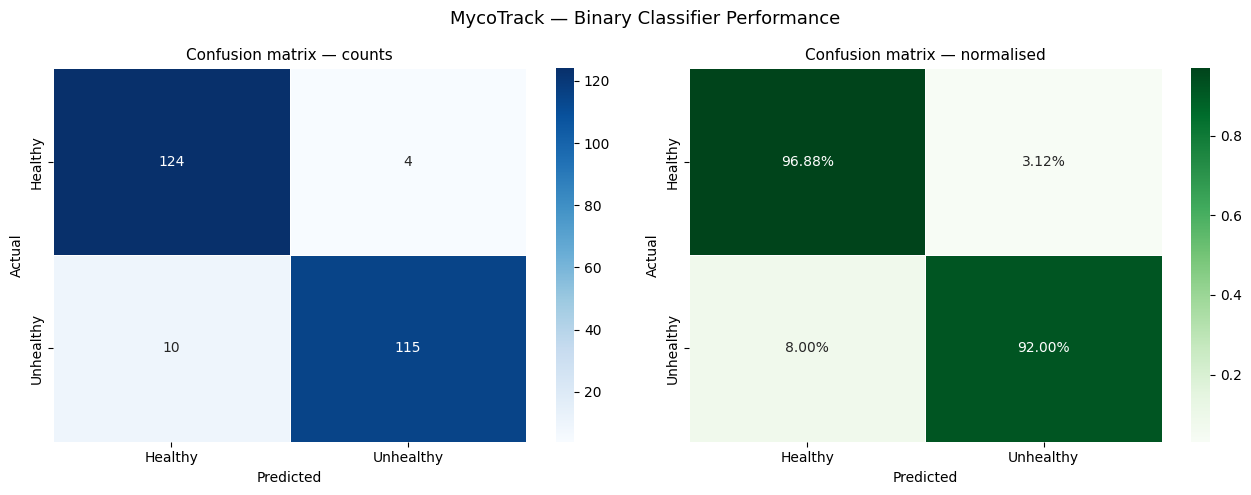

True Healthy correctly called healthy    : 124
Unhealthy missed (false negatives)       : 10  ← most important to minimise
Healthy incorrectly flagged (false pos.) : 4
Unhealthy correctly detected             : 115
Recall (unhealthy detection rate)        : 92.00%


In [ ]:
cm      = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, data, fmt, title, cmap in [
    (axes[0], cm,      'd',    'Confusion matrix — counts',      'Blues'),
    (axes[1], cm_norm, '.2%', 'Confusion matrix — normalised',  'Greens'),
]:
    sns.heatmap(data, annot=True, fmt=fmt, cmap=cmap, ax=ax,
                xticklabels=DISPLAY_CLASSES, yticklabels=DISPLAY_CLASSES,
                linewidths=0.5)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Predicted', fontsize=10)
    ax.set_ylabel('Actual',    fontsize=10)

plt.suptitle('MycoTrack — Binary Classifier Performance', fontsize=13)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# Clinical interpretation
tn, fp, fn, tp = cm.ravel()
print(f'True Healthy correctly called healthy    : {tn}')
print(f'Unhealthy missed (false negatives)       : {fn}  ← most important to minimise')
print(f'Healthy incorrectly flagged (false pos.) : {fp}')
print(f'Unhealthy correctly detected             : {tp}')
print(f'Recall (unhealthy detection rate)        : {tp/(tp+fn):.2%}')

## 14 · Prediction grid (visual spot-check)

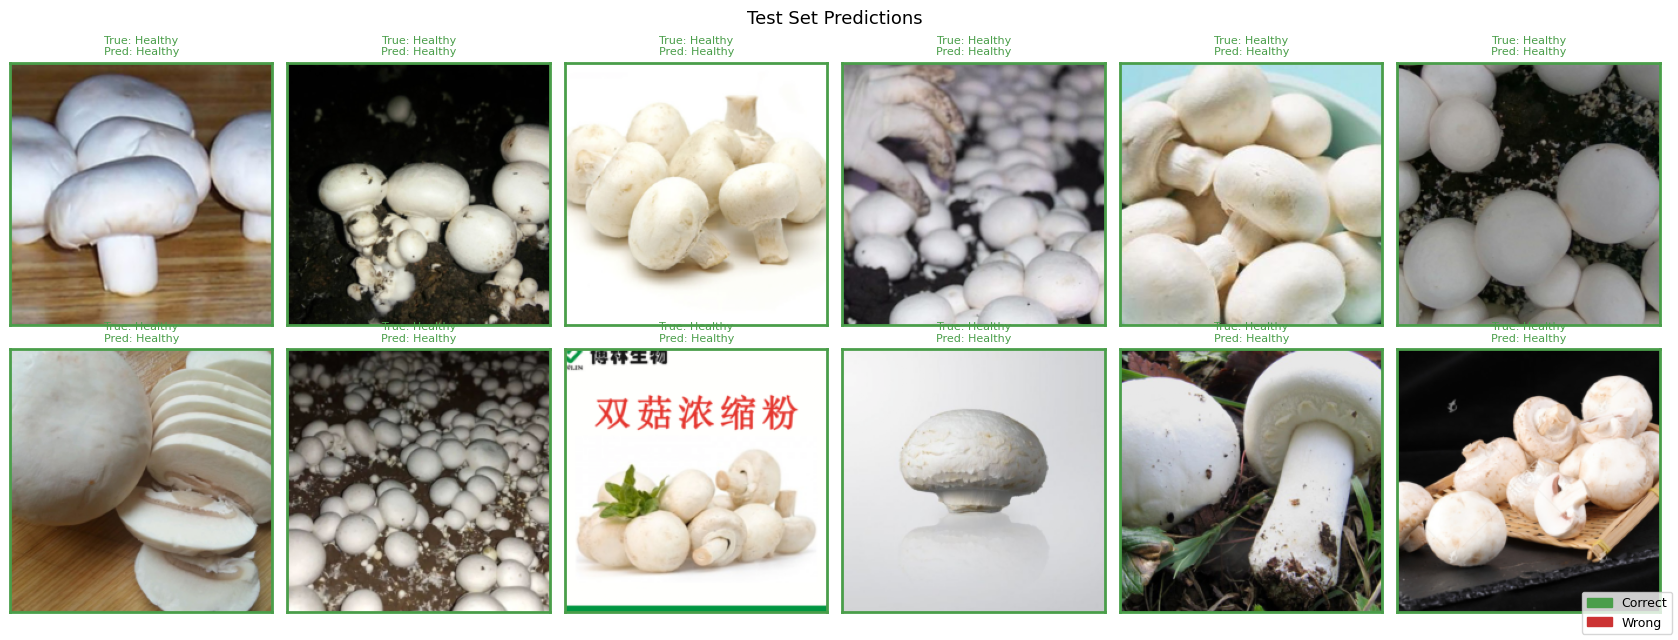

In [ ]:
@torch.no_grad()
def prediction_grid(model, loader, display_classes, device, n=12):
    model.eval()
    mean = torch.tensor(MEAN).view(3,1,1)
    std  = torch.tensor(STD).view(3,1,1)
    collected_imgs, collected_true, collected_pred = [], [], []

    for imgs, labels in loader:
        out   = model(imgs.to(device))
        preds = out.argmax(1).cpu()
        collected_imgs.extend(imgs)
        collected_true.extend(labels)
        collected_pred.extend(preds)
        if len(collected_imgs) >= n:
            break

    cols = 6
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.8, rows * 3.2))
    axes = axes.flatten()

    for i in range(n):
        img  = (collected_imgs[i] * std + mean).clamp(0, 1).permute(1,2,0).numpy()
        true = display_classes[collected_true[i]]
        pred = display_classes[collected_pred[i]]
        ok   = true == pred
        axes[i].imshow(img)
        axes[i].set_title(
            f'True: {true}\nPred: {pred}',
            fontsize=8,
            color='#4a9e4a' if ok else '#cc3333',
        )
        for spine in axes[i].spines.values():
            spine.set_edgecolor('#4a9e4a' if ok else '#cc3333')
            spine.set_linewidth(2)
        axes[i].axis('off') if not ok else axes[i].set_xticks([])
        axes[i].set_yticks([])

    for j in range(n, len(axes)):
        axes[j].axis('off')

    green_p = mpatches.Patch(color='#4a9e4a', label='Correct')
    red_p   = mpatches.Patch(color='#cc3333', label='Wrong')
    fig.legend(handles=[green_p, red_p], loc='lower right', fontsize=9)

    plt.suptitle('Test Set Predictions', fontsize=13)
    plt.tight_layout()
    plt.savefig('predictions_grid.png', dpi=150, bbox_inches='tight')
    plt.show()


prediction_grid(model, test_loader, DISPLAY_CLASSES, DEVICE)

## 15 · Save weights — `mushroom_cls.pth`

The file is saved as a **raw state_dict** matching what `realtime_mushroom.py` expects:  
```python
state = torch.load(CLASSIFIER_WEIGHTS, map_location=DEVICE)
model.load_state_dict(state)
```
> ⚠️ If you trained **ResNet-50**, you must also update `get_classifier()` in  
> `realtime_mushroom.py` to load `resnet50` instead of `resnet18`.  
> The cell below prints the exact lines to paste.

In [ ]:
# Save state_dict only (what the backend loads)
torch.save(model.state_dict(), OUTPUT_WEIGHTS)

print(f'  Saved: {OUTPUT_WEIGHTS}')
print(f'    Architecture : {ARCH}')
print(f'    Val accuracy : {best_val_acc:.4f}')
print(f'    Test accuracy: {acc:.4f}')
print(f'    Test AUC     : {auc:.4f}')
print()

if ARCH == 'resnet50':
    print('─' * 60)
    print('  Paste this into realtime_mushroom.py → get_classifier():')
    print('─' * 60)
    print('''
    model = tv_models.resnet50(weights=None)
    model.fc = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(2048, 512),
        nn.ReLU(inplace=True),
        nn.Dropout(p=0.3),
        nn.Linear(512, 2),
    )
''')
else:
    print('  ResNet-18 weights — no backend changes needed.')
    print('    Place mushroom_cls.pth next to realtime_mushroom.py and run.')

  Saved: /content/drive/MyDrive/MycoTrack/mushroom_cls.pth
    Architecture : resnet50
    Val accuracy : 0.9640
    Test accuracy: 0.9447
    Test AUC     : 0.9787

────────────────────────────────────────────────────────────
  Paste this into realtime_mushroom.py → get_classifier():
────────────────────────────────────────────────────────────

    model = tv_models.resnet50(weights=None)
    model.fc = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(2048, 512),
        nn.ReLU(inplace=True),
        nn.Dropout(p=0.3),
        nn.Linear(512, 2),
    )



## 16 · Single-image inference (for testing)

In [ ]:
def predict_image(image_path: str, model, display_classes: list, device: str):
    """
    Run inference on a single image.  Same pre-processing as the FastAPI backend.
    Returns: (label, confidence, probabilities_dict)
    """
    tf = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    img    = Image.open(image_path).convert('RGB')
    tensor = tf(img).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(tensor), dim=1)[0].cpu()

    pred_idx = probs.argmax().item()
    label    = display_classes[pred_idx]
    conf     = probs[pred_idx].item()
    prob_dict = {display_classes[i]: round(probs[i].item(), 4) for i in range(len(display_classes))}

    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].imshow(img)
    axes[0].set_title(f'{label}  ({conf*100:.1f}%)',
                      color='#4a9e4a' if label=='Healthy' else '#cc3333',
                      fontsize=12, fontweight='bold')
    axes[0].axis('off')

    colors = ['#4a9e4a' if c == 'Healthy' else '#cc3333' for c in display_classes]
    axes[1].barh(display_classes, [prob_dict[c] for c in display_classes], color=colors)
    axes[1].set_xlim(0, 1)
    axes[1].set_xlabel('Probability')
    axes[1].set_title('Class probabilities')
    for i, v in enumerate([prob_dict[c] for c in display_classes]):
        axes[1].text(v + 0.01, i, f'{v*100:.1f}%', va='center', fontsize=10)

    plt.tight_layout()
    plt.show()
    return label, conf, prob_dict


# Usage:
# label, conf, probs = predict_image('my_mushroom.jpg', model, DISPLAY_CLASSES, DEVICE)
print('predict_image() is ready. Call it with any image path.')

predict_image() is ready. Call it with any image path.


In [ ]:
# ── Persist everything to Google Drive ───────────────────────────────────
import shutil, os
from pathlib import Path

def save_to_drive(src, drive_dir=DRIVE_DIR):
    src = Path(src)
    dst = Path(drive_dir) / src.name
    if src.is_dir():
        shutil.copytree(src, dst, dirs_exist_ok=True)
    else:
        shutil.copy2(src, dst)
    print(f'✅  {src}  →  {dst}')


# save_to_drive('mushroom_cls.pth')      # ResNet classifier weights
# save_to_drive('/content/aug_samples.png')
# save_to_drive('/content/confusion_matrix.png')
save_to_drive('/content/predictions_grid.png')
save_to_drive('/content/training_curves.png')

print('\n🎉  All saved to Google Drive permanently!')

FileNotFoundError: [Errno 2] No such file or directory: 'mushroom_cls.pth'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import shutil
from pathlib import Path

DRIVE_DIR = '/content/drive/MyDrive/MycoTrack'

for item in Path(DRIVE_DIR).iterdir():
    dst = Path('/content') / item.name
    if item.is_dir():
        shutil.copytree(item, dst, dirs_exist_ok=True)
    else:
        shutil.copy2(item, dst)
    print(f'✅  Restored: {item.name}')

## 17 · Deployment checklist

```
├── realtime_mushroom.py      ← FastAPI backend (unchanged for ResNet-18)
├── mushroom_cls.pth          ← ✅  output of this notebook
├── mushroom_yolo.pt          ← your YOLO weights (or yolov8n.pt fallback)
└── requirements.txt
```

**React Native app → backend flow:**
1. App captures frame → `POST /realtime_frame` (multipart JPEG)
2. Backend: YOLO locates mushrooms → ResNet classifies crops → Groq writes report → TTS audio
3. JSON returned: `{ objects, warnings, narration, audio_b64, summary, timestamp }`
4. App draws bounding boxes, plays audio, navigates to Disease Result screen if `summary.unhealthy > 0`

**Backend start:**
```bash
pip install fastapi uvicorn ultralytics torch torchvision TTS soundfile groq
python realtime_mushroom.py
```

**Health check:**
```bash
curl http://localhost:8000/health
```